# Movie Genre Classification – EDA & Results

CodSoft ML Internship · Task 1

This notebook walks through the analysis using the reusable modules in `src/`. The heavy lifting (tuning, refitting, final evaluation) is done by `python train.py`; this notebook reads its saved reports.

In [1]:
import sys, json
from pathlib import Path
ROOT = Path.cwd().parent if Path.cwd().name == 'notebooks' else Path.cwd()
sys.path.insert(0, str(ROOT))
import pandas as pd
from IPython.display import Image, display
from src.data_loader import load_train_data, load_test_data
from src.eda import dataset_summary
from src.preprocessing import clean_text, build_text

## 1. Load and inspect the dataset

In [2]:
train, train_report = load_train_data()
test, test_report = load_test_data()
print(train_report.as_dict())
print(test_report.as_dict())
train.head()

{'file': 'train_data.txt', 'kind': 'train', 'total_lines': 54214, 'parsed_records': 54214, 'blank_lines': 0, 'empty_descriptions': 0, 'malformed_lines': 0, 'malformed_examples': []}
{'file': 'test_data.txt', 'kind': 'test', 'total_lines': 54200, 'parsed_records': 54200, 'blank_lines': 0, 'empty_descriptions': 0, 'malformed_lines': 0, 'malformed_examples': []}


,id,title,genre,description
0,1,Oscar et la dame rose (2009),drama,Listening in to a conversation between his doc...
1,2,Cupid (1997),thriller,A brother and sister with a past incestuous re...
2,3,"Young, Wild and Wonderful (1980)",adult,As the bus empties the students for their fiel...
3,4,The Secret Sin (1915),drama,To help their unemployed father make ends meet...
4,5,The Unrecovered (2007),drama,The film's title refers not only to the un-rec...


## 2. Missing values, duplicates and imbalance

In [3]:
summary = dataset_summary(train, test)
{k: v for k, v in summary.items() if k not in ('genre_counts', 'median_words_by_genre', 'description_words')}

{'train_records': 54214,
 'test_records': 54200,
 'n_genres': 27,
 'columns_train': ['id', 'title', 'genre', 'description'],
 'columns_test': ['id', 'title', 'description'],
 'missing_values_train': {'id': 0, 'title': 0, 'genre': 0, 'description': 0},
 'empty_descriptions_train': 0,
 'empty_descriptions_test': 0,
 'duplicate_ids_train': 0,
 'duplicate_rows_train': 0,
 'duplicate_descriptions_train': 128,
 'duplicate_descriptions_conflicting_genre': 15,
 'train_descriptions_also_in_test': 164,
 'imbalance_ratio_largest_to_smallest': 103.12878787878788}

In [4]:
pd.Series(summary['genre_counts']).to_frame('movies').assign(share=lambda d: (d.movies / d.movies.sum()).round(4))

,movies,share
drama,13613,0.2511
documentary,13096,0.2416
comedy,7447,0.1374
short,5073,0.0936
horror,2204,0.0407
thriller,1591,0.0293
action,1315,0.0243
western,1032,0.0190
reality-tv,884,0.0163
family,784,0.0145


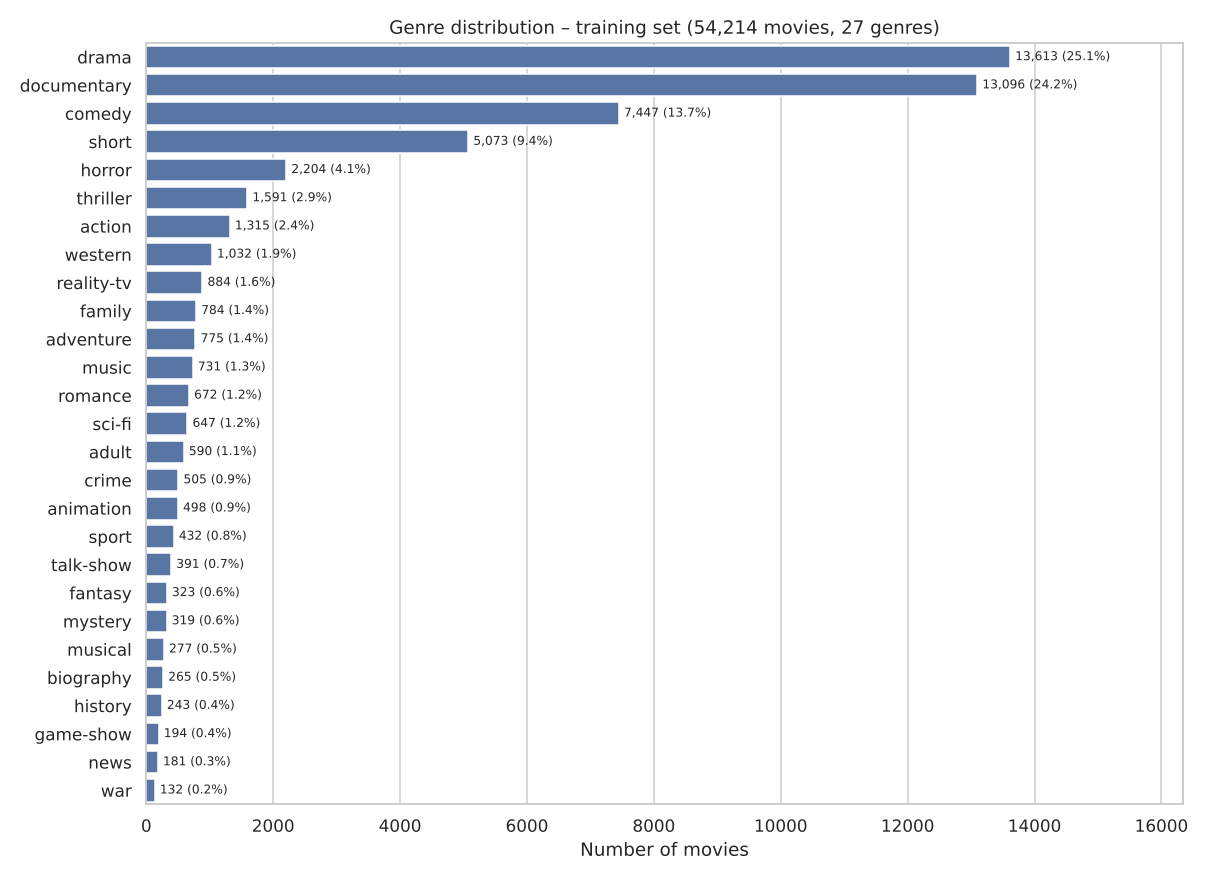

In [5]:
display(Image(str(ROOT / 'reports/figures/genre_distribution.png')))

## 3. Plot description lengths

count    54214.0
mean       101.9
std         76.6
min          6.0
25%         55.0
50%         79.0
75%        121.0
95%        242.0
max       1829.0
dtype: float64


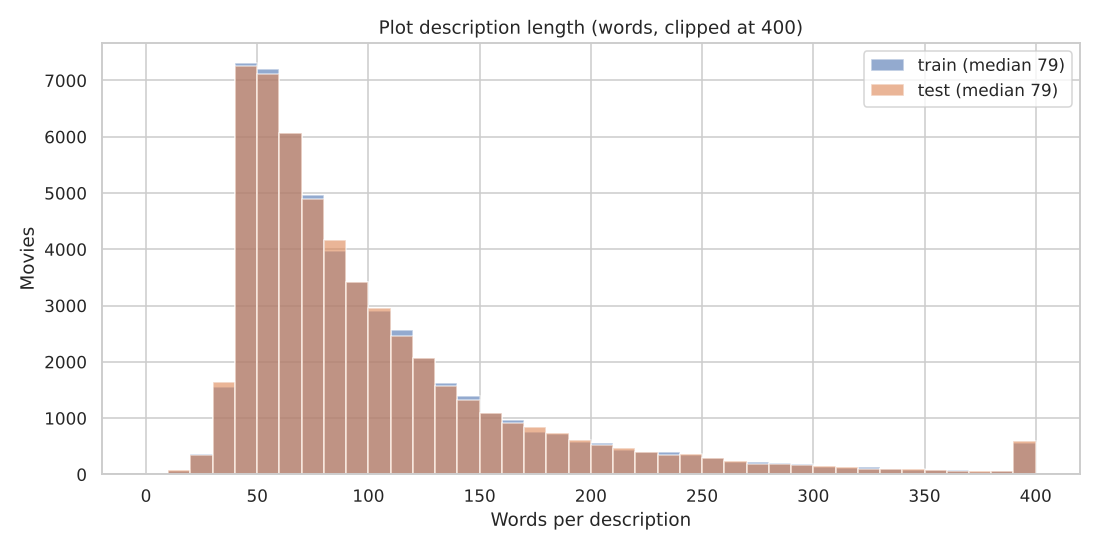

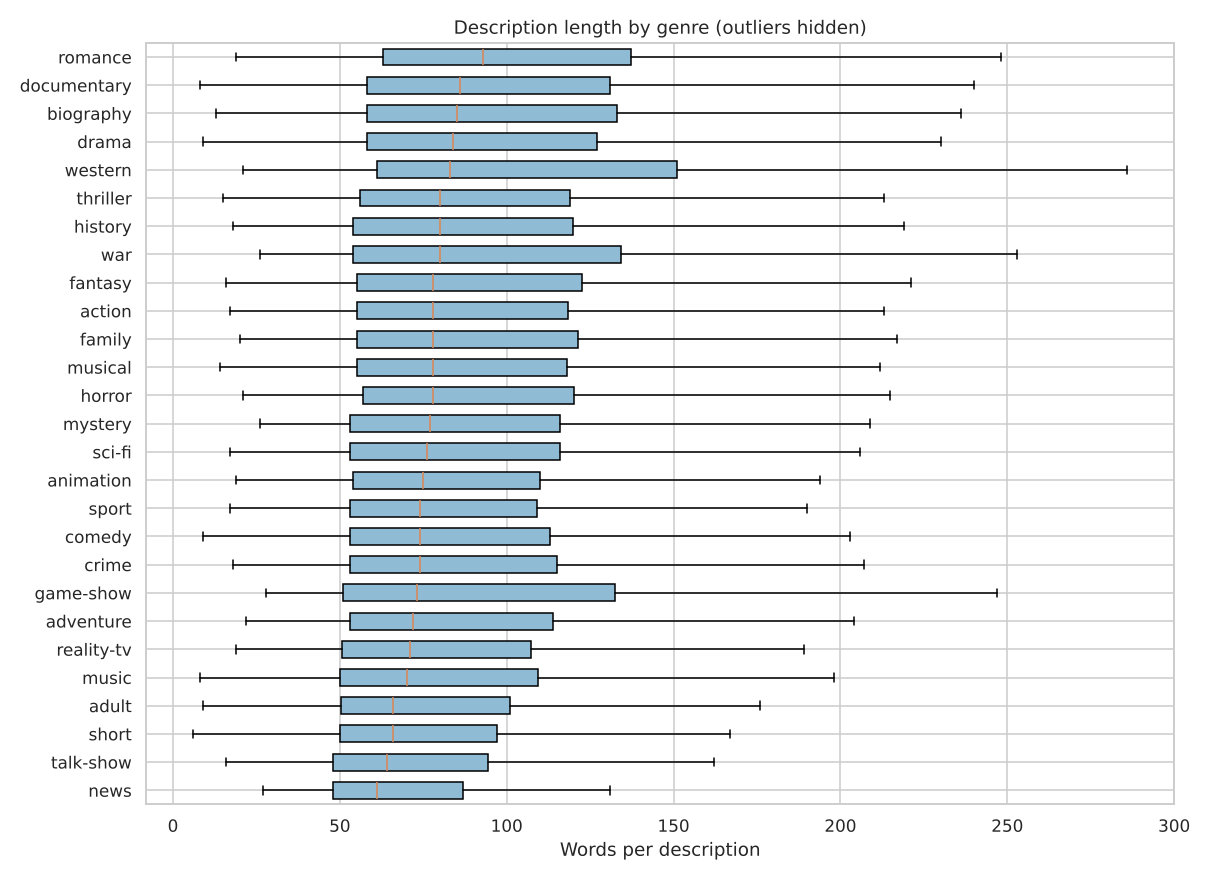

In [6]:
print(pd.Series(summary['description_words']).round(1))
display(Image(str(ROOT / 'reports/figures/description_length_distribution.png')))
display(Image(str(ROOT / 'reports/figures/description_length_by_genre.png')))

## 4. Common and distinctive words by genre

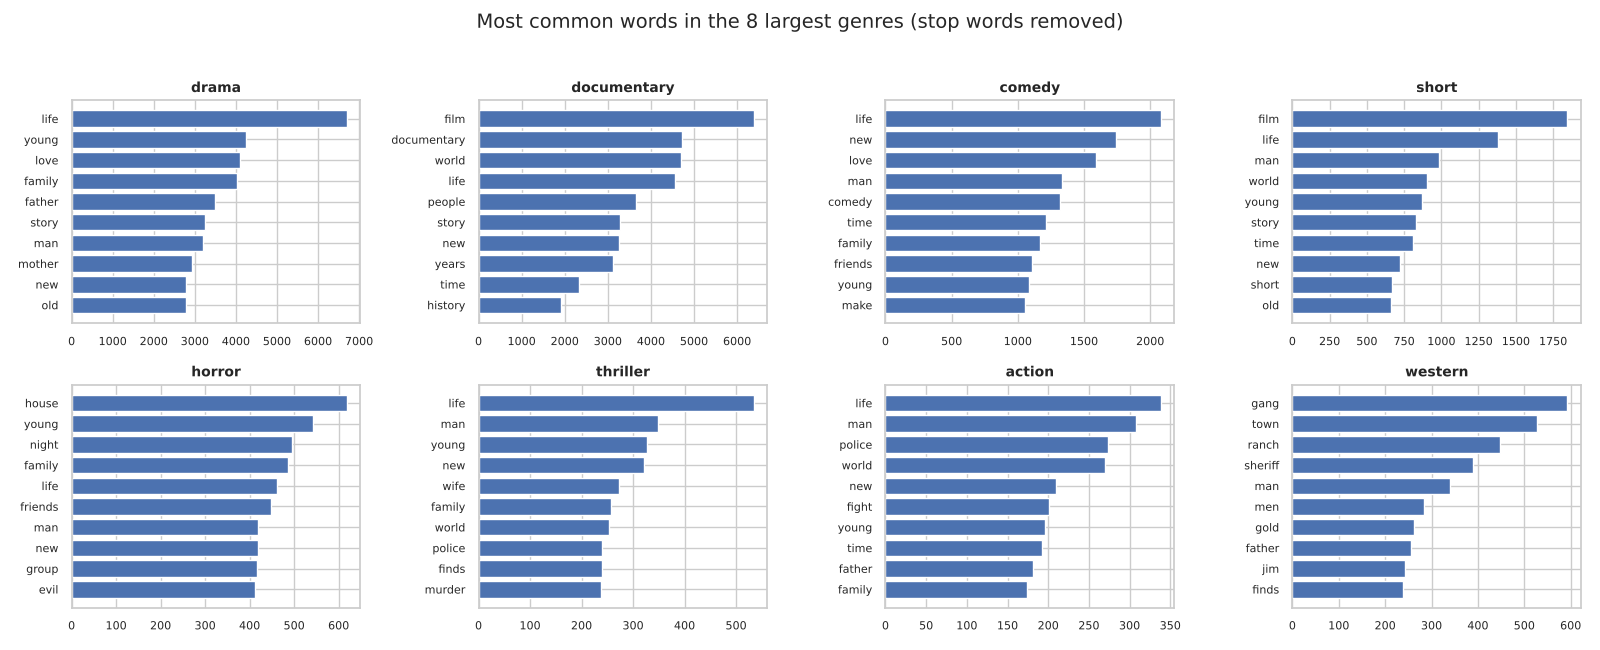

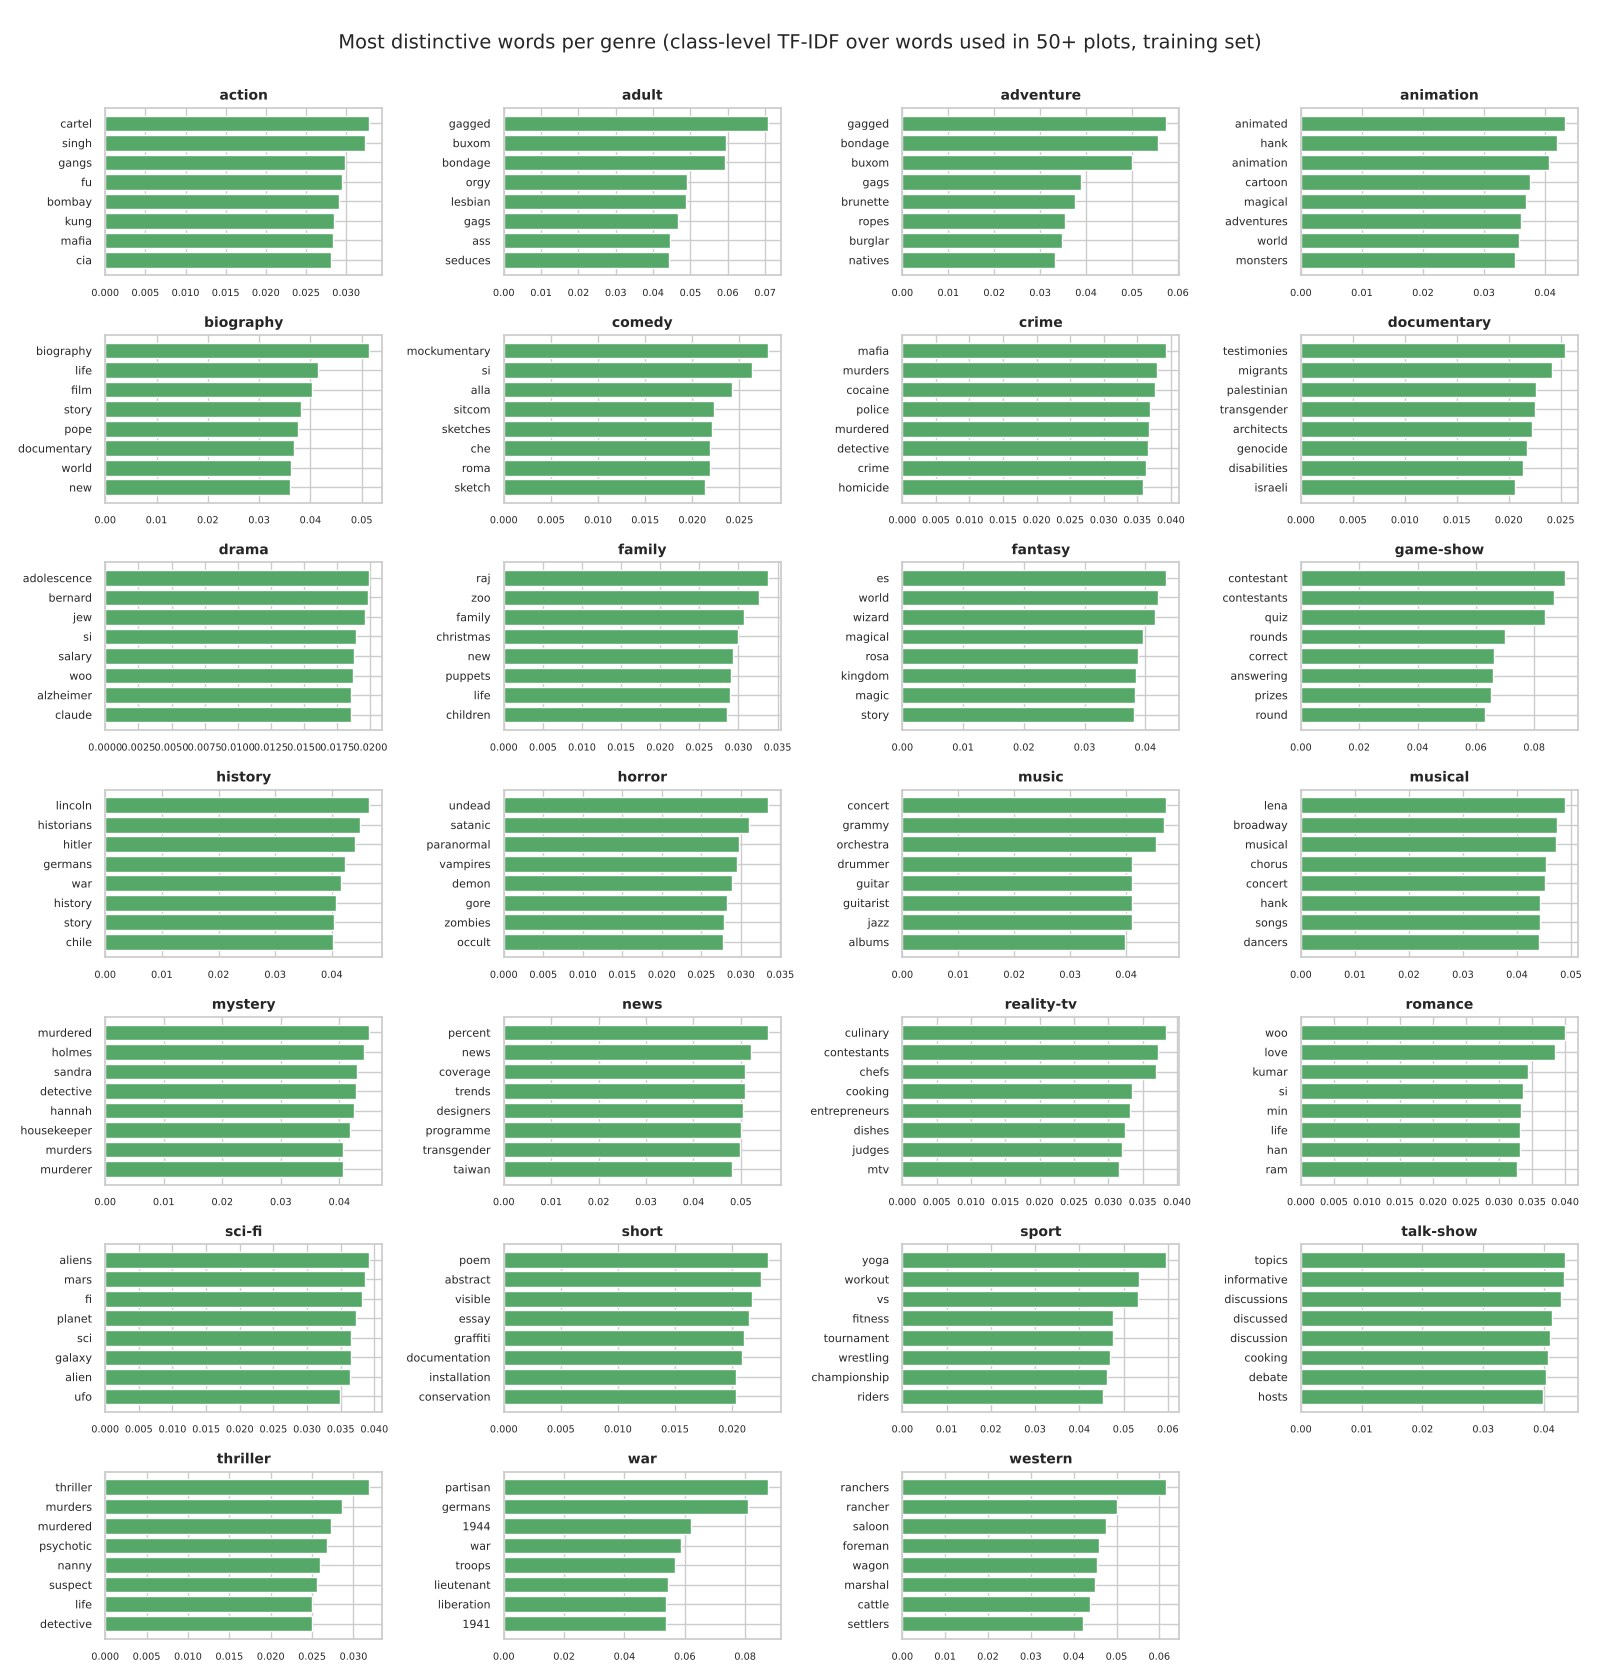

In [7]:
display(Image(str(ROOT / 'reports/figures/common_words_by_genre.png')))
display(Image(str(ROOT / 'reports/figures/top_words_by_genre.png')))

## 5. Text cleaning example

In [8]:
row = train.iloc[0]
print('RAW :', row.title, '|', row.description[:200])
print('CLEAN:', clean_text(build_text(row.title, row.description))[:200])

RAW : Oscar et la dame rose (2009) | Listening in to a conversation between his doctor and parents, 10-year-old Oscar learns what nobody has the courage to tell him. He only has a few weeks to live. Furious, he refuses to speak to anyone
CLEAN: oscar et la dame rose listening in to a conversation between his doctor and parents 10 year old oscar learns what nobody has the courage to tell him he only has a few weeks to live furious he refuses 


## 6. Model comparison

Models were tuned and **selected on a stratified 20% validation split** of `train_data.txt` (macro-F1). The official test labels were used only once afterwards.

In [9]:
pd.read_csv(ROOT / 'reports/validation_model_comparison.csv')

,model,key,best_params,accuracy,macro_precision,macro_recall,macro_f1,weighted_f1
0,TF-IDF + Logistic Regression,logistic_regression,"{""C"": 5.0, ""class_weight"": ""balanced""}",0.587752,0.416664,0.438967,0.421452,0.587352
1,TF-IDF + Linear SVM,linear_svm,"{""C"": 0.3, ""class_weight"": null}",0.616158,0.505901,0.369360,0.404954,0.592003
2,TF-IDF + Multinomial Naive Bayes,naive_bayes,"{""alpha"": 0.01, ""fit_prior"": false}",0.563221,0.400878,0.368660,0.370678,0.547469
3,Word2Vec embeddings + Logistic Regression (sup...,word2vec_logreg,"{""C"": 1.0, ""class_weight"": null}",0.552246,0.409318,0.281141,0.310941,0.519464


In [10]:
pd.read_csv(ROOT / 'reports/test_model_comparison.csv')

,model,key,selected,accuracy,macro_precision,macro_recall,macro_f1,weighted_f1
0,TF-IDF + Logistic Regression,logistic_regression,True,0.591605,0.416756,0.443135,0.423589,0.593087
1,TF-IDF + Linear SVM,linear_svm,False,0.621900,0.507358,0.374538,0.412571,0.597545
2,TF-IDF + Multinomial Naive Bayes,naive_bayes,False,0.570387,0.393368,0.378633,0.376945,0.557115
3,Word2Vec embeddings + Logistic Regression (sup...,word2vec_logreg,False,0.562860,0.397475,0.280579,0.310216,0.529855


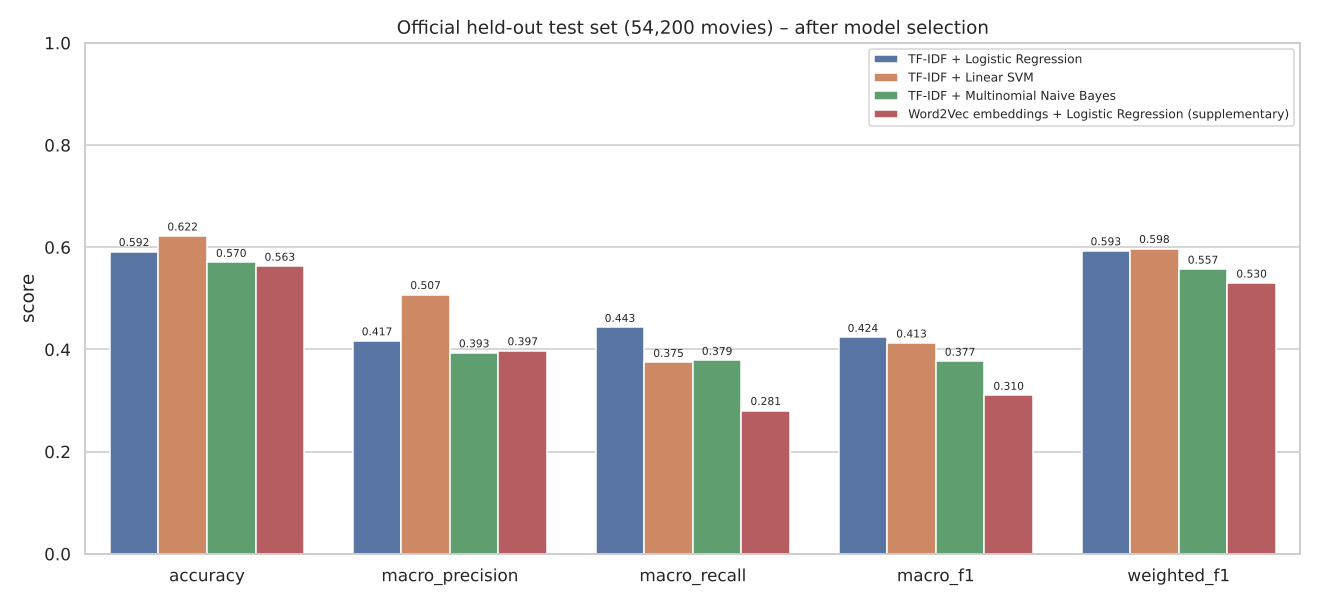

In [11]:
display(Image(str(ROOT / 'reports/figures/model_comparison_test.png')))

## 7. Selected model – per-genre results and confusion matrix

In [12]:
pd.read_csv(ROOT / 'reports/per_genre_metrics_test.csv')

,genre,precision,recall,f1,support
0,drama,0.679600,0.594475,0.634194,13612
1,documentary,0.774357,0.745266,0.759533,13096
2,comedy,0.600929,0.608112,0.604499,7446
3,short,0.451309,0.472397,0.461613,5072
4,horror,0.597863,0.710980,0.649534,2204
5,thriller,0.300380,0.347799,0.322355,1590
6,action,0.405296,0.535769,0.461488,1314
7,western,0.824577,0.897287,0.859397,1032
8,reality-tv,0.398668,0.474519,0.433299,883
9,family,0.280000,0.295019,0.287313,783


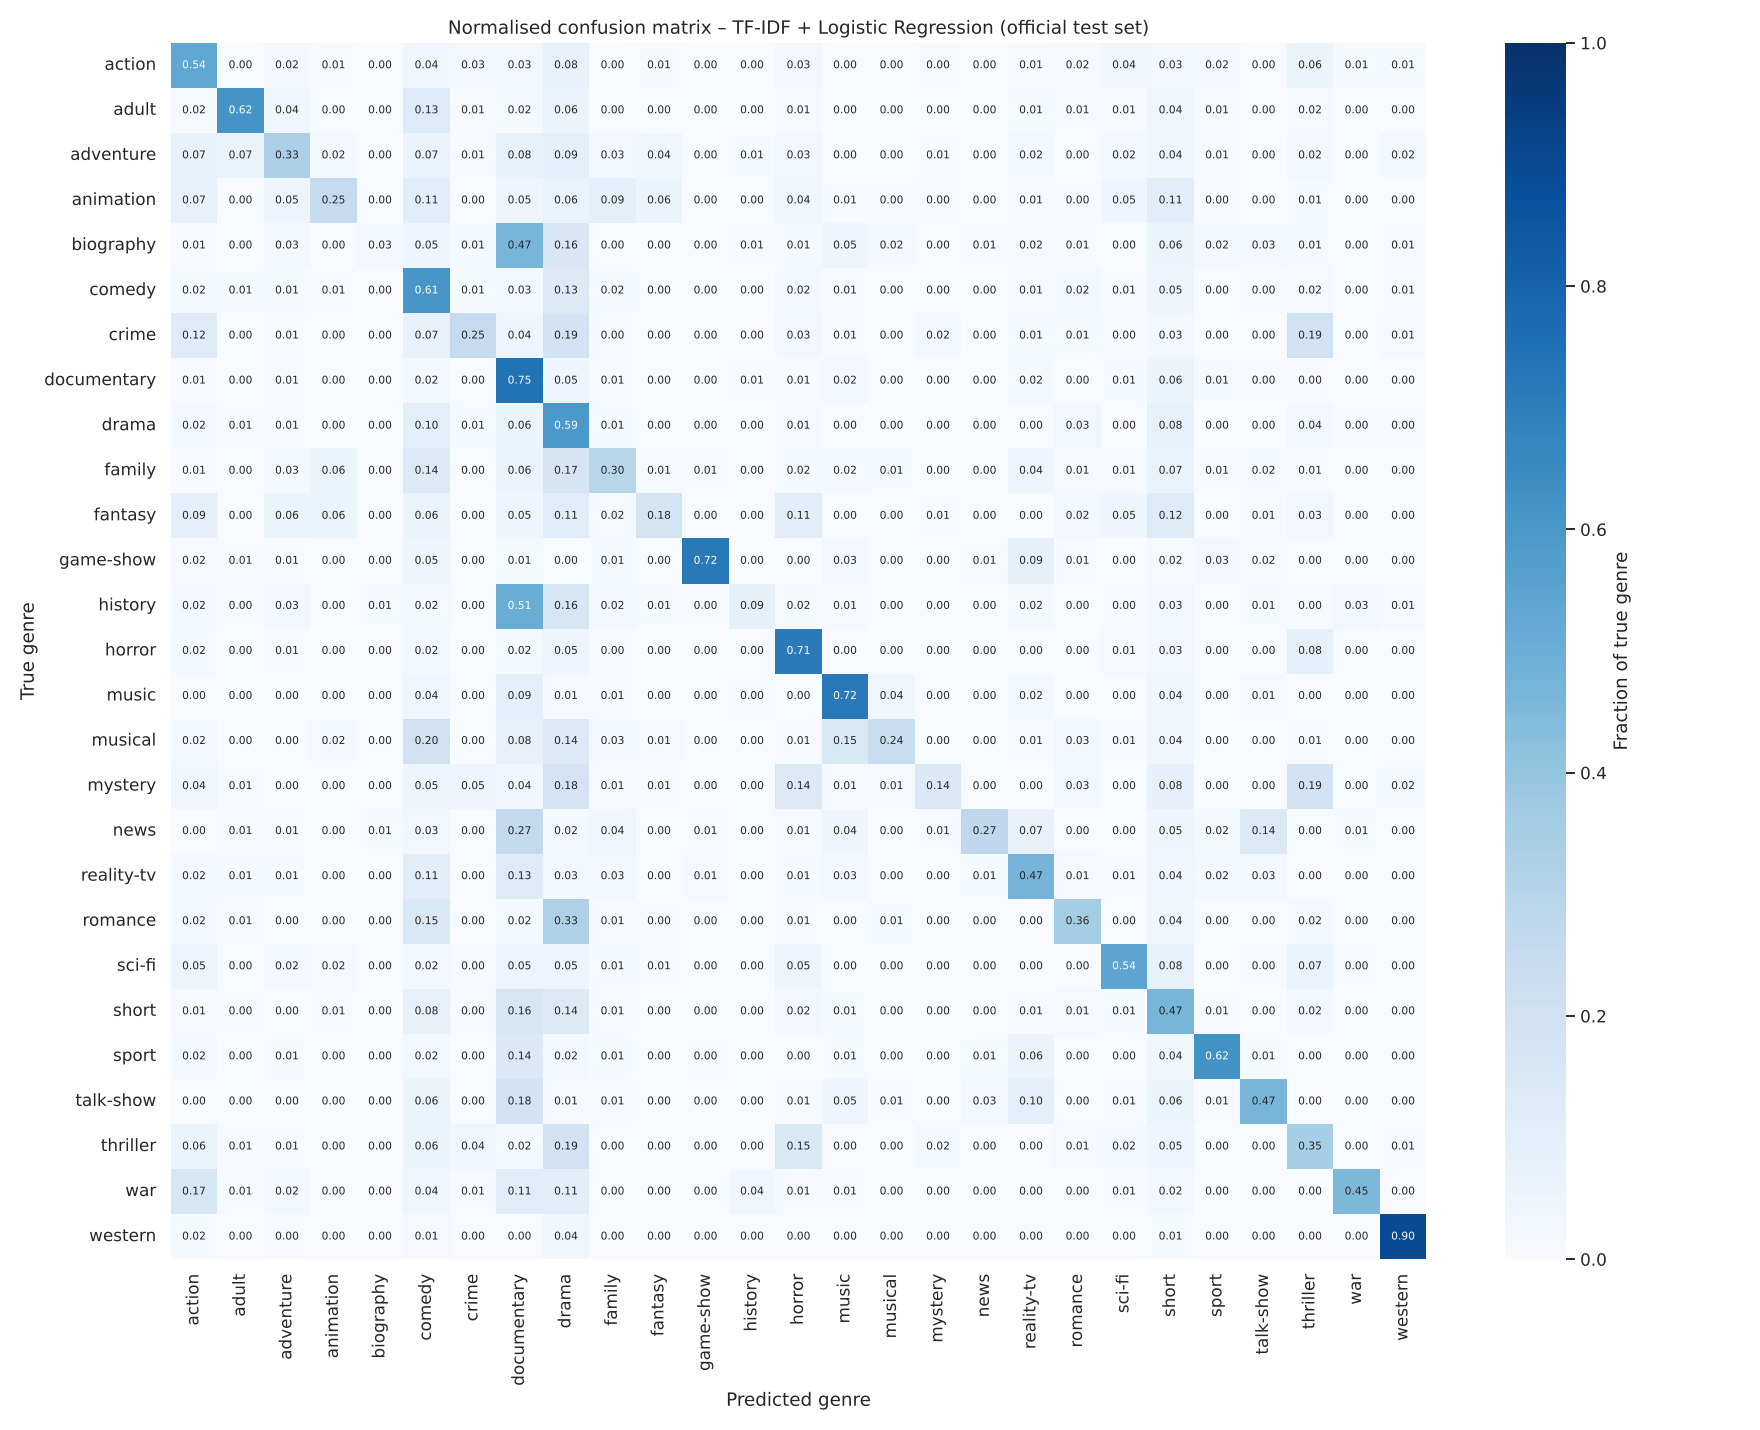

In [13]:
display(Image(str(ROOT / 'reports/figures/confusion_matrix_test.png')))

## 8. Using the saved pipeline

In [14]:
from src.predictor import GenrePredictor
p = GenrePredictor.load()
p.predict('A retired gunslinger defends the ranchers of a frontier town from a gang of outlaws.', title='Dust and Iron')

{'genre': 'western',
 'confidence': 0.9893368482589722,
 'top_k': [{'genre': 'western', 'score': 0.9893368482589722},
  {'genre': 'action', 'score': 0.0015142476186156273},
  {'genre': 'short', 'score': 0.001356307533569634}]}